# Phase 2: melody + genre + mode → Roman-numeral progression

## tl;dr
This is an executable experiment ladder, using `03_phase2_clean_dataset`'s saved snapshot. It runs a tiny-window memorization probe, two fixed priors, a local melody MLP, a small transformer, and a balanced transformer with root/quality/change auxiliary tasks. A second stage tests two smaller harmonic transformers with multi-scale chroma and chord-tone evidence after inspecting the first ladder. It selects on **validation only**, optionally tunes transition decoding there, freezes a portable inference bundle, and evaluates the selected system on the test split.

**Executed result:** the selected transformer reaches 51.52% validation accuracy and 44.64% test accuracy, below the mode-only priors (53.87% and 45.45%). It improves minority/chord-change metrics, but tonic overprediction remains. The notebook records this limitation rather than claiming the task is solved.

All reported results below come from executed cells. The old notebook's saved temporal experiment achieved ~53.57% validation accuracy and macro-F1 ~0.065, with persistent tonic collapse. Our filtered cohort/features differ slightly, so that number is context, not an exact controlled comparison. The new baselines use exactly the same new examples as the new transformers.

## Context & Methods

Your earlier note encoder → beat-query cross-attention → beat encoder is a sensible starting point, but its saved attention was close to uniform and pitch shuffling barely affected predictions. This version gives **every beat direct local melody evidence**: four ordered pitch/coverage/contour/onset slots, plus onset chroma and meter. A short convolution precedes two independently initialized self-attention layers. There is no previous ground-truth chord input and no teacher-forcing mismatch.

### Key Assumptions

- Full melody windows are available: attention is bidirectional, suitable for offline harmonization. This is not a streaming causal model.
- Inputs are key- and global-octave invariant but retain rhythm, chromatic pitches and relative contour. Genre is multi-label, fitted only from training-song tags; unseen genres use `<unknown>`.
- Output is one Roman chord per beat, then run-length encoding produces chord order **with durations**. It cannot recover sub-beat chord changes with this target resolution.
- All learned models use the same train-only song-balanced sampler. Capped square-root class weights are an experiment, not assumed to help. The structured version also learns root, quality and change targets; its change head is auxiliary, while decoding uses train-only transition counts.
- Selection score, declared before training: `0.5 × macro-F1 + 0.3 × accuracy + 0.2 × exact-beat change-F1`. No hyperparameter uses the test scores. Root/quality scores, non-tonic accuracy, song-average accuracy, segment edit similarity and input ablations diagnose different failure modes.
- Macro-F1 averages target-supported classes. Change-F1 compares adjacent **valid** beat pairs at exact boundaries. Segment edit similarity collapses repeats inside each contiguous valid region and averages those regions; it is not a standard audio chord-recognition score.
- These are extracted reference chords, not the only valid harmonization of a melody. Automated exact-label accuracy cannot replace listening.

Reference APIs: [PyTorch TransformerEncoderLayer](https://docs.pytorch.org/docs/2.12/generated/torch.nn.TransformerEncoderLayer.html) and [CrossEntropyLoss](https://docs.pytorch.org/docs/2.12/generated/torch.nn.CrossEntropyLoss.html). Actual installed versions are recorded below and in the exported bundle.

### 1. Setup and reproducible controls

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "datasets/mtg-jamendo/melody-chord-extraction-pipeline").is_dir())
NOTEBOOKS = PROJECT / "experiments/pasan/notebooks"
sys.path.insert(0, str(NOTEBOOKS))
SNAPSHOT = NOTEBOOKS / "phase2_dataset_v2"
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "axes.axisbelow": True})
BLUE, GOLD, PINK = "#2864A0", "#B17A12", "#AB5178"
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_rows", 16)

In [2]:
import torch, platform
from dataclasses import asdict
from phase2_harmony.data import load_snapshot, LABELS, FAMILIES, file_hash
from phase2_harmony.model import (ModelConfig, HarmonyModel, seed_everything, device_available,
    make_loader, overfit_probe, train_experiment, baseline_predictions, metrics,
    predict, evaluate, score, transition_log_probs, viterbi, harmonize, load_bundle)
arrays, examples, metadata = load_snapshot(SNAPSHOT)
DEVICE = device_available()
SEED, EPOCHS = 42, 20
REFINEMENT_EPOCHS = 30
RUNS = NOTEBOOKS / "phase2_runs_v2"
RUNS.mkdir(exist_ok=True)
seed_everything(SEED)
print({"python":platform.python_version(), "torch":torch.__version__, "numpy":np.__version__,
       "device":DEVICE, "epochs":EPOCHS, "snapshot":str(SNAPSHOT)})
print("Checkpoint resume: identical configurations reuse/continue prior runs; use a new RUNS for a fresh experiment.")
val_loader = make_loader(arrays, examples, "validation")
train_indices = np.flatnonzero(examples.split.to_numpy() == "train")
val_indices = np.flatnonzero(examples.split.to_numpy() == "validation")

{'python': '3.12.13', 'torch': '2.13.0', 'numpy': '2.5.2', 'device': 'mps', 'epochs': 20, 'snapshot': '/Users/praise/Developer/vocal-harmonization/experiments/pasan/notebooks/phase2_dataset_v2'}
Checkpoint resume: identical configurations reuse/continue prior runs; use a new RUNS for a fresh experiment.


## Data
### 2. Check the contract and memorize a tiny batch
This probe uses **four training windows only**. Its purpose is to expose alignment, masking, optimization or capacity bugs before judging generalization. A good memorization score does not measure model quality.

In [3]:
probe = overfit_probe(arrays, examples, len(metadata["genre_vocab"]), device=DEVICE)
display(pd.Series(probe).to_frame("probe"))
assert probe["training_accuracy"] > .95, "Resolve memorization failure before full training."
assert examples.groupby("artist_id").split.nunique().max() == 1
assert arrays["x"].shape[-1] == 77
print("Original tonic/key are absent from model inputs. Mode and normalized melody are retained.")

,probe
windows,4.000000
steps,180.000000
training_accuracy,1.000000
loss,0.000289


Original tonic/key are absent from model inputs. Mode and normalized melody are retained.


### 3. Fixed baselines on the same validation population

In [4]:
idx, prior_predictions = baseline_predictions(arrays, examples, "validation")
prior_results = {}
for name, pred in prior_predictions.items():
    prior_results[name] = metrics(arrays["y"][idx], pred, arrays["lengths"][idx],
                                 arrays["mode"][idx], examples.iloc[idx].track_id.to_numpy())
display(pd.DataFrame(prior_results).T[["accuracy","macro_f1","change_f1","non_tonic_accuracy","predicted_tonic_fraction"]].round(4))

,accuracy,macro_f1,change_f1,non_tonic_accuracy,predicted_tonic_fraction
majority,0.3317,0.0128,0.0,0.0077,0.5859
mode_only,0.5387,0.0352,0.0,0.0000,1.0000


## Results
### 4. Train a controlled experiment ladder
Start with a small local model; add sequence context; then add imbalance compensation and auxiliary tasks.

**Refinement after the first ladder:** initial models still hovered near the mode prior, although shifting melody pitch sharply reduced their validation accuracy. A training-only check found more melody mass on the reference chord tones than on arbitrary chord templates. The two `harmonic_*` runs therefore add chroma context at 1/3/7/15 beats, a learned linear skip and a soft chord-tone template skip, with one 64-wide attention layer and stronger dropout. Non-chord melody tones remain allowed. This refinement used validation evidence only; the test split was still closed. Each checkpoint is selected using the same validation score and patience. Training is deterministic on this CPU run; accelerator kernels can have small numerical differences.

Inspect the implementation in `phase2_harmony/model.py`; `HarmonyModel`, `loss_function`, `metrics`, and `train_experiment` are separate functions so each experiment can be changed independently. No hidden training service is involved.

In [5]:
EXPERIMENTS = [
    ("local_mlp", ModelConfig(architecture="mlp"), False, False, EPOCHS),
    ("transformer_ce", ModelConfig(), False, False, EPOCHS),
    ("transformer_balanced", ModelConfig(), True, True, EPOCHS),
    ("harmonic_transformer", ModelConfig(width=64,layers=1,dropout=.25,architecture="harmonic_transformer"), False, True, REFINEMENT_EPOCHS),
    ("harmonic_balanced", ModelConfig(width=64,layers=1,dropout=.25,architecture="harmonic_transformer"), True, True, REFINEMENT_EPOCHS),
]
models, histories, checkpoints = {}, [], {}
for name, config, balanced, structured, epochs in EXPERIMENTS:
    model, history, checkpoint = train_experiment(
        name, arrays, examples, len(metadata["genre_vocab"]), RUNS,
        epochs=epochs, balanced=balanced, structured=structured, config=config,
        seed=SEED, device=DEVICE, dataset_fingerprint=file_hash(SNAPSHOT / "metadata.json"))
    models[name], checkpoints[name] = model, checkpoint
    histories.append(history)
history = pd.concat(histories, ignore_index=True)
comparison = pd.DataFrame([{ "model":name, "best_epoch":checkpoints[name]["epoch"],
    "train_accuracy":evaluate(model, make_loader(arrays,examples,"train"),arrays,examples,DEVICE)["accuracy"],
    **evaluate(model, val_loader, arrays, examples, DEVICE)} for name,model in models.items()])
comparison["selection_score"] = comparison.apply(lambda row: score(row), axis=1)
display(comparison[["model","best_epoch","train_accuracy","accuracy","macro_f1","change_f1","non_tonic_accuracy","song_macro_accuracy","selection_score"]].round(4))
comparison.to_csv(RUNS / "validation_comparison.csv", index=False)

,model,best_epoch,train_accuracy,accuracy,macro_f1,change_f1,non_tonic_accuracy,song_macro_accuracy,selection_score
0,local_mlp,10,0.4786,0.5357,0.0565,0.1835,0.0837,0.5625,0.2257
1,transformer_ce,5,0.4828,0.5152,0.0666,0.1898,0.1319,0.5406,0.2259
2,transformer_balanced,10,0.5159,0.4944,0.0685,0.1993,0.1354,0.5224,0.2225
3,harmonic_transformer,10,0.4894,0.5282,0.0677,0.1662,0.1203,0.5527,0.2255
4,harmonic_balanced,10,0.4874,0.5233,0.0675,0.1716,0.1279,0.5454,0.2251


### 5. Learning curves and class collapse checks

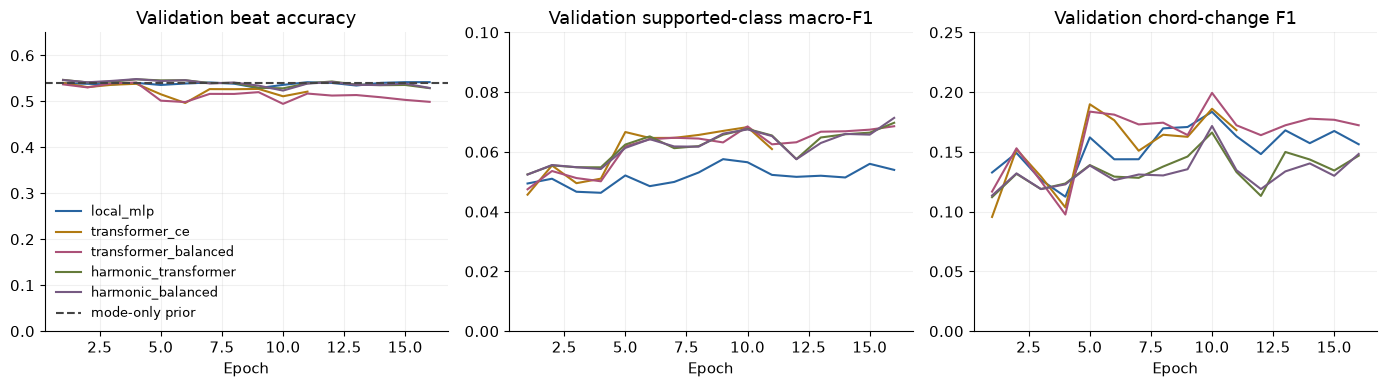

,model,actual_tonic_fraction,predicted_tonic_fraction,root_accuracy,quality_accuracy,segment_edit_similarity,top3_accuracy
0,local_mlp,0.5387,0.8659,0.5721,0.7303,0.3680,0.7683
1,transformer_ce,0.5387,0.7615,0.5501,0.7105,0.3635,0.7699
2,transformer_balanced,0.5387,0.7233,0.5347,0.6920,0.3548,0.7639
3,harmonic_transformer,0.5387,0.8028,0.5629,0.7211,0.3728,0.7709
4,harmonic_balanced,0.5387,0.7816,0.5600,0.7162,0.3664,0.7687


Frozen architecture/checkpoint winner: transformer_ce epoch 5


In [6]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for (name, group), color in zip(history.groupby("experiment",sort=False), [BLUE,GOLD,PINK,"#657B3A","#765A82"]):
    for ax, metric, title in zip(axes,["accuracy","macro_f1","change_f1"],
                                ["Validation beat accuracy","Validation supported-class macro-F1","Validation chord-change F1"]):
        ax.plot(group.epoch,group[metric],label=name,color=color)
        ax.set(title=title,xlabel="Epoch",ylim=(0,1))
for ax, upper in zip(axes,[.65,.10,.25]):
    ax.set_ylim(0,upper)
axes[0].axhline(prior_results["mode_only"]["accuracy"],color="#444444",ls="--",label="mode-only prior")
axes[0].legend(frameon=False,fontsize=9)
plt.tight_layout(); plt.show()
display(comparison[["model","actual_tonic_fraction","predicted_tonic_fraction","root_accuracy","quality_accuracy","segment_edit_similarity","top3_accuracy"]].round(4))
winner_name = comparison.sort_values(["selection_score","model"],ascending=[False,True]).iloc[0]["model"]
winner = models[winner_name]
print("Frozen architecture/checkpoint winner:", winner_name, "epoch", checkpoints[winner_name]["epoch"])

### 6. Does the chosen transformer use the melody, genre and mode?
These are held-out validation perturbations on exactly the same windows. Zeroing melody removes pitch, local rhythm and contour; reversing melody changes local order while retaining beat/meter positions; wrong-pitch shifts chroma by five semitones while keeping the supplied tonic fixed. They are diagnostic distribution shifts, not separate training experiments. A small genre effect can mean weak use, noisy tags or limited power; it does not prove genres are irrelevant.

,condition,accuracy,macro_f1,change_f1,accuracy_drop,macro_f1_drop
0,original,0.5152,0.0666,0.1898,0.0000,0.0000
1,no_melody,0.5300,0.0384,0.0238,-0.0147,0.0283
2,reverse_melody,0.4602,0.0479,0.1529,0.0551,0.0187
3,wrong_pitch,0.2783,0.0402,0.1863,0.2369,0.0264
4,no_genre,0.5165,0.0662,0.1909,-0.0012,0.0004
5,wrong_mode,0.1533,0.0216,0.1760,0.3620,0.0451


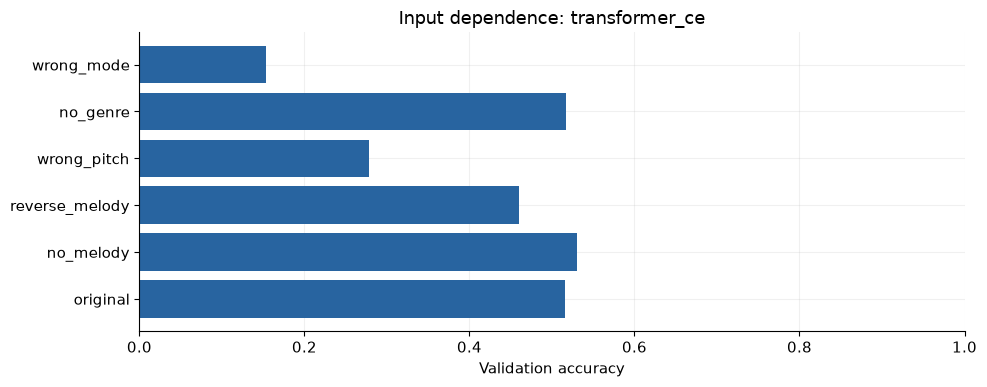

In [7]:
ablation_rows=[]
for condition in [None,"no_melody","reverse_melody","wrong_pitch","no_genre","wrong_mode"]:
    result=evaluate(winner,val_loader,arrays,examples,DEVICE,ablation=condition)
    ablation_rows.append({"condition":condition or "original",**result})
ablations=pd.DataFrame(ablation_rows)
ablations["accuracy_drop"] = ablations.iloc[0].accuracy - ablations.accuracy
ablations["macro_f1_drop"] = ablations.iloc[0].macro_f1 - ablations.macro_f1
display(ablations[["condition","accuracy","macro_f1","change_f1","accuracy_drop","macro_f1_drop"]].round(4))
ablations.to_csv(RUNS / "validation_ablations.csv",index=False)
fig, ax=plt.subplots(figsize=(10,4))
ax.barh(ablations.condition,ablations.accuracy,color=BLUE)
ax.set(title=f"Input dependence: {winner_name}",xlabel="Validation accuracy",xlim=(0,1))
plt.tight_layout();plt.show()

### 7. Decode progression continuity using training transitions
Viterbi decoding combines model logits with a train-only, mode-conditioned chord transition prior. Its weight is chosen from the declared small validation grid, including **zero**. No reference masks or reference chord boundaries enter decoding. Smoothing can improve continuity while destroying real changes, so raw and decoded metrics are both retained. If all learned systems fail to beat the mode-only validation baseline, the notebook records that rather than claiming success.

In [8]:
transition = transition_log_probs(arrays, examples)
raw_pred, val_logits, val_idx = predict(winner,val_loader,DEVICE)
decode_rows=[]
for alpha in [0., .15, .4]:
    pred=viterbi(val_logits,arrays["lengths"][val_idx],arrays["mode"][val_idx],transition,alpha)
    result=metrics(arrays["y"][val_idx],pred,arrays["lengths"][val_idx],arrays["mode"][val_idx],
                   examples.iloc[val_idx].track_id.to_numpy())
    decode_rows.append({"alpha":alpha,"selection_score":score(result),**result})
decoding=pd.DataFrame(decode_rows)
ALPHA=float(decoding.sort_values(["selection_score","alpha"],ascending=[False,True]).iloc[0].alpha)
display(decoding[["alpha","accuracy","macro_f1","change_f1","segment_edit_similarity","selection_score"]].round(4))
print("Frozen decoder weight:",ALPHA)
final_val_pred=viterbi(val_logits,arrays["lengths"][val_idx],arrays["mode"][val_idx],transition,ALPHA)
decoding.to_csv(RUNS / "validation_decoder.csv",index=False)

,alpha,accuracy,macro_f1,change_f1,segment_edit_similarity,selection_score
0,0.00,0.5152,0.0666,0.1898,0.3635,0.2259
1,0.15,0.5248,0.0642,0.1353,0.3781,0.2166
2,0.40,0.5282,0.0574,0.0879,0.3686,0.2047


Frozen decoder weight: 0.0


### 8. Which chords are learned?

,roman,support,predicted,recall,f1
1,i:MIN,9157,12646,0.841,0.706
0,I:MAJ,6204,8558,0.783,0.658
45,IV:MAJ,2453,1959,0.238,0.265
72,bVI:MAJ,2224,2432,0.282,0.269
46,iv:MIN,1522,455,0.131,0.201
90,bVII:MAJ,1224,190,0.030,0.052
63,V:MAJ,995,786,0.202,0.226
27,bIII:MAJ,685,18,0.004,0.009
64,v:MIN,442,85,0.000,0.000
2,I:DOM7,425,0,0.000,0.000


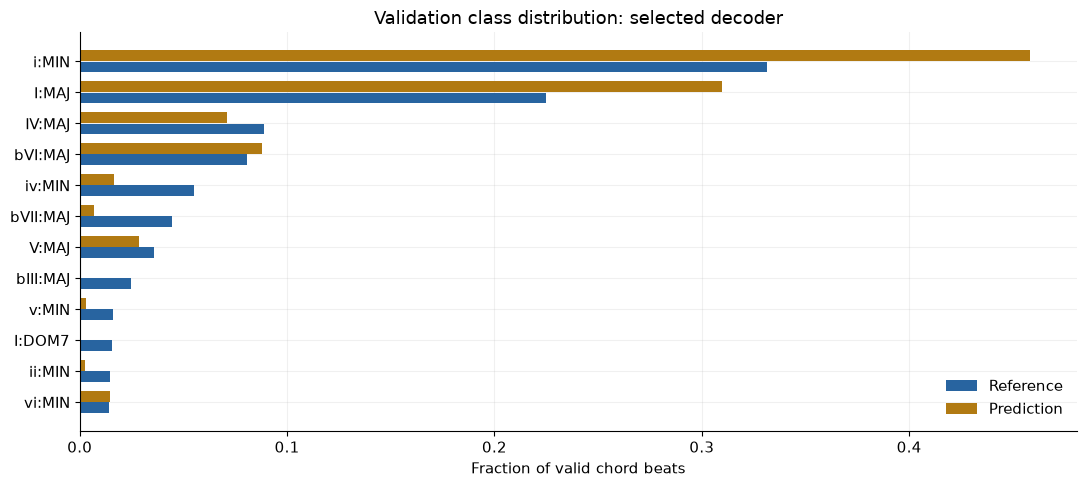

In [9]:
valid=arrays["y"][val_idx]>=0
yt,yp=arrays["y"][val_idx][valid],final_val_pred[valid]
support=np.bincount(yt,minlength=len(LABELS)); predicted=np.bincount(yp,minlength=len(LABELS))
correct=np.bincount(yt[yt==yp],minlength=len(LABELS))
per_class=pd.DataFrame({"roman":LABELS,"support":support,"predicted":predicted,
                        "recall":correct/np.maximum(support,1),
                        "f1":2*correct/np.maximum(support+predicted,1)})
display(per_class[per_class.support>0].sort_values("support",ascending=False).head(16).round(3))
per_class.to_csv(RUNS / "validation_per_class.csv",index=False)
top=np.argsort(support)[-12:];pos=np.arange(len(top))
fig,ax=plt.subplots(figsize=(11,5))
ax.barh(pos-.18,support[top]/support.sum(),height=.35,color=BLUE,label="Reference")
ax.barh(pos+.18,predicted[top]/predicted.sum(),height=.35,color=GOLD,label="Prediction")
ax.set_yticks(pos,[LABELS[i] for i in top]);ax.set(title="Validation class distribution: selected decoder",xlabel="Fraction of valid chord beats")
ax.legend(frameon=False);plt.tight_layout();plt.show()

### 8b. Repeat the frozen architecture across training seeds
These repeats diagnose validation stability after architecture selection. They do not replace the seed-42 checkpoint or choose a seed using the test split. The saved table includes the selection seed for comparison.

In [10]:
seed_results=[{"seed":SEED,**evaluate(winner,val_loader,arrays,examples,DEVICE)}]
for repeat_seed in [7,123]:
    repeated,_,state=train_experiment(
        f"{winner_name}_seed{repeat_seed}",arrays,examples,len(metadata["genre_vocab"]),RUNS,
        epochs=checkpoints[winner_name]["params"]["epochs"],
        balanced=checkpoints[winner_name]["params"]["balanced"],
        structured=checkpoints[winner_name]["params"]["structured"],config=winner.config,
        seed=repeat_seed,device=DEVICE,dataset_fingerprint=file_hash(SNAPSHOT / "metadata.json"))
    seed_results.append({"seed":repeat_seed,**evaluate(repeated,val_loader,arrays,examples,DEVICE)})
seed_table=pd.DataFrame(seed_results)
display(seed_table[["seed","accuracy","macro_f1","change_f1","non_tonic_accuracy"]].round(4))
seed_table.to_csv(RUNS / "validation_seed_stability.csv",index=False)

,seed,accuracy,macro_f1,change_f1,non_tonic_accuracy
0,42,0.5152,0.0666,0.1898,0.1319
1,7,0.5205,0.0702,0.1773,0.1325
2,123,0.5337,0.0654,0.1462,0.1069


### 9. Freeze the portable inference bundle, then evaluate test once
Only the selected architecture/checkpoint and validation-chosen decoder are tested here, alongside fixed baselines. Test metrics are recorded for reporting, not used to change the configuration. Future model changes should be judged on validation or a new development split; repeated adaptation to these test numbers would invalidate the holdout.

In [11]:
bundle=RUNS / "selected_bundle"
bundle.mkdir(exist_ok=True)
torch.save({"state_dict":{k:v.detach().cpu() for k,v in winner.state_dict().items()},
            "model_config":asdict(winner.config)},bundle / "model.pt")
np.save(bundle / "transition.npy",transition,allow_pickle=False)
bundle_meta={"winner":winner_name,"epoch":checkpoints[winner_name]["epoch"],
             "alpha":ALPHA,"genre_vocab":metadata["genre_vocab"],"labels":LABELS,
             "clean_config":metadata["clean_config"],"feature_schema":"phase2_harmony.data.melody_features v1, 77 features",
             "dataset_metadata_sha256":file_hash(SNAPSHOT / "metadata.json"),
             "torch":torch.__version__,"numpy":np.__version__,"python":platform.python_version(),
             "model_sha256":file_hash(bundle / "model.pt"),"transition_sha256":file_hash(bundle / "transition.npy"),
             "implementation_sha256":{p.name:file_hash(p) for p in (NOTEBOOKS / "phase2_harmony").glob("*.py")}}
import shutil
(bundle / "phase2_harmony").mkdir(exist_ok=True)
for source in (NOTEBOOKS / "phase2_harmony").glob("*.py"):
    shutil.copy2(source,bundle / "phase2_harmony" / source.name)
(bundle / "metadata.json").write_text(json.dumps(bundle_meta,indent=2))
test_loader=make_loader(arrays,examples,"test")
test_pred,test_logits,test_idx=predict(winner,test_loader,DEVICE)
test_decoded=viterbi(test_logits,arrays["lengths"][test_idx],arrays["mode"][test_idx],transition,ALPHA)
test_results={}
for name,pred in [("selected_raw",test_pred),("selected_decoded",test_decoded),
                  *baseline_predictions(arrays,examples,"test")[1].items()]:
    test_results[name]=metrics(arrays["y"][test_idx],pred,arrays["lengths"][test_idx],arrays["mode"][test_idx],
                               examples.iloc[test_idx].track_id.to_numpy())
test_table=pd.DataFrame(test_results).T
display(test_table[["accuracy","macro_f1","change_f1","non_tonic_accuracy","song_macro_accuracy","segment_edit_similarity"]].round(4))
test_table.to_csv(RUNS / "test_results.csv")
print("Portable bundle:",bundle)

,accuracy,macro_f1,change_f1,non_tonic_accuracy,song_macro_accuracy,segment_edit_similarity
selected_raw,0.4464,0.0575,0.1892,0.1324,0.4441,0.3465
selected_decoded,0.4464,0.0575,0.1892,0.1324,0.4441,0.3465
majority,0.3877,0.0143,0.0000,0.0002,0.3752,0.2647
mode_only,0.4545,0.0289,0.0000,0.0000,0.4522,0.3055


Portable bundle: /Users/praise/Developer/vocal-harmonization/experiments/pasan/notebooks/phase2_runs_v2/selected_bundle


### 9b. Uncertainty and mode slices for the fixed test result
A paired artist bootstrap resamples held-out artists (2,000 draws) and recomputes the beat-weighted accuracy difference from the mode-only prior. It captures artist sampling variability conditional on these trained weights and pseudo-labels; it does not measure annotation uncertainty. Test slices below are descriptive and do not alter model selection.

In [12]:
reference=arrays["y"][test_idx];valid=reference>=0
mode_prior=baseline_predictions(arrays,examples,"test")[1]["mode_only"]
artist_rows=pd.DataFrame({"artist":examples.iloc[test_idx].artist_id.to_numpy(),
    "correct_model":((test_decoded==reference)&valid).sum(1),
    "correct_prior":((mode_prior==reference)&valid).sum(1),"beats":valid.sum(1)})
artist_counts=artist_rows.groupby("artist")[["correct_model","correct_prior","beats"]].sum().to_numpy()
rng=np.random.default_rng(2026)
resampled=artist_counts[rng.integers(len(artist_counts),size=(2000,len(artist_counts)))].sum(1)
delta=(resampled[:,0]-resampled[:,1])/resampled[:,2]
ci=np.quantile(delta,[.025,.975])
print(f"Model minus mode-only accuracy: {(test_results['selected_decoded']['accuracy']-test_results['mode_only']['accuracy'])*100:+.2f} pp")
print(f"95% paired artist-bootstrap interval: [{ci[0]*100:+.2f}, {ci[1]*100:+.2f}] pp; {len(artist_counts)} held-out artists")
slices=[]
for mode_name,mode_id in [("major",0),("minor",1)]:
    select=arrays["mode"][test_idx]==mode_id
    slices.append({"mode":mode_name,"songs":examples.iloc[test_idx[select]].track_id.nunique(),
        **metrics(reference[select],test_decoded[select],arrays["lengths"][test_idx][select],
                  arrays["mode"][test_idx][select],examples.iloc[test_idx[select]].track_id.to_numpy())})
display(pd.DataFrame(slices)[["mode","songs","accuracy","macro_f1","change_f1","non_tonic_accuracy"]].round(4))
(RUNS / "test_accuracy_uncertainty.json").write_text(json.dumps({"artist_count":len(artist_counts),"draws":2000,"difference_95ci":ci.tolist()}))

Model minus mode-only accuracy: -0.81 pp
95% paired artist-bootstrap interval: [-3.05, +1.61] pp; 31 held-out artists


,mode,songs,accuracy,macro_f1,change_f1,non_tonic_accuracy
0,major,14,0.4506,0.0737,0.2360,0.2154
1,minor,65,0.4456,0.0413,0.1761,0.1142


101

### 10. Honest sample output and whole-song inference
Load the saved weights in a fresh model and pass **only melody, mode, genre and beat/meter timing**. The example below rebuilds inputs from saved cleaned notes; it does not pass any reference chord to `harmonize`. An eight-bar validation window is used so its alignment can be inspected. For a longer song, inference averages overlapping 48-beat windows, then decodes the full song.

For normalized MIDI, set `normalized=True`: C major uses tonic pitch class 0, A minor uses 9. For original-key MIDI, supply the actual `tonic_pc`. MIDI numbers carry melody contour; only invariant relative features reach the model. If you start with scale degrees rather than MIDI, preserve accidental and octave/contour information when converting them to the reference scale. Meter defaults to 4/4 only when omitted; supply actual beat records for other meters.

In [13]:
loaded,bundle_meta,loaded_transition=load_bundle(bundle)
# First validation example is deterministic; no selection by prediction quality.
sample_id=int(val_idx[0]);sample=examples.iloc[sample_id]
clean_row=next(json.loads(line) for line in (SNAPSHOT / "cleaned_notes.jsonl").open()
               if json.loads(line)["track_id"] == sample.track_id)
# Recover only the normalization tonic from raw key metadata, never chord labels.
raw_key=json.loads((PROJECT / "datasets/mtg-jamendo/melody-chord-extraction-pipeline/outputs" /
                    sample.track_id / "key.json").read_text())["melody_key"]["selected"]
notes=[{"onset_sec":n["onset_sec"],"offset_sec":n["offset_sec"],
        "midi_pitch_rounded":n["pitch"]} for n in clean_row["notes"]]
# Reuse metrical positions saved as the last five input features.
n=int(arrays["lengths"][sample_id]);bounds=sample.beat_boundaries_sec
num=int(round(arrays["x"][sample_id,0,75]*12));den=int(round(arrays["x"][sample_id,0,76]*8))
beat_records=[{"beat_in_bar":i%num+1,"meter_numerator":num,"meter_denominator":den} for i in range(n)]
result=harmonize(loaded,notes,bounds,sample["mode"],list(sample.genres),bundle_meta["genre_vocab"],
                 tonic_pc=int(raw_key["tonic_pc"]),beats=beat_records,transition=loaded_transition,alpha=ALPHA)
np.testing.assert_allclose(result["logits"], val_logits[0,:n],rtol=1e-4,atol=1e-4)
display(pd.DataFrame(result["progression"]))
print("Chord order:"," → ".join(event["roman"] for event in result["progression"]))
reference_tonic=0 if sample["mode"]=="major" else 9
shift=reference_tonic-int(raw_key["tonic_pc"])
example_input={"notes":[{**note,"midi_pitch_rounded":note["midi_pitch_rounded"]+shift}
                        for note in notes if note["onset_sec"] < bounds[-1] and note["offset_sec"] > bounds[0]],
               "beat_boundaries":bounds.tolist(),"mode":sample["mode"],
               "genres":list(sample.genres),"normalized":True,"beats":beat_records}
(bundle / "example_input.json").write_text(json.dumps(example_input,indent=2))
normalized_result=harmonize(loaded,example_input["notes"],bounds,sample["mode"],list(sample.genres),
    bundle_meta["genre_vocab"],normalized=True,beats=beat_records,transition=loaded_transition,alpha=ALPHA)
np.testing.assert_allclose(result["logits"],normalized_result["logits"],atol=1e-5)
print("Original-key and C-major/A-minor normalized inference agree.")
display(pd.DataFrame({"beat":np.arange(n),
    "reference":[LABELS[v] if v>=0 else "MASKED" for v in arrays["y"][sample_id,:n]],
    "prediction":result["beat_chords"]}).head(20))

,start_beat,end_beat,start_sec,end_sec,roman
0,0,20,0.00,9.03,i:MIN
1,20,21,9.03,9.49,bVII:MAJ
2,21,32,9.49,14.45,i:MIN


Chord order: i:MIN → bVII:MAJ → i:MIN
Original-key and C-major/A-minor normalized inference agree.


,beat,reference,prediction
0,0,MASKED,i:MIN
1,1,i:MIN,i:MIN
2,2,i:MIN,i:MIN
3,3,i:MIN,i:MIN
4,4,i:MIN,i:MIN
...,...,...,...
15,15,i:MIN,i:MIN
16,16,i:MIN,i:MIN
17,17,i:MIN,i:MIN
18,18,i:MIN,i:MIN


### 11. Record the observed result and decision

In [14]:
chosen=decoding.loc[decoding.alpha==ALPHA].iloc[0]
base=prior_results["mode_only"]
melody_drop=float(ablations.loc[ablations.condition=="no_melody","accuracy_drop"].iloc[0])
summary={"winner":winner_name,"epoch":checkpoints[winner_name]["epoch"],"alpha":ALPHA,
         "validation_accuracy":float(chosen.accuracy),"validation_macro_f1":float(chosen.macro_f1),
         "validation_change_f1":float(chosen.change_f1),"mode_only_accuracy":base["accuracy"],
         "melody_ablation_accuracy_drop":melody_drop,"test":test_results,
         "limitation":"architecture selection at one seed; separate validation seed repeats; strict key-selected pseudo-label cohort; listening validation remains necessary"}
(RUNS / "summary.json").write_text(json.dumps(summary,indent=2))
display(Markdown(f"**Selected:** `{winner_name}`, epoch {summary['epoch']}, decoder weight {ALPHA}. "
    f"Validation accuracy **{chosen.accuracy:.1%}**, macro-F1 **{chosen.macro_f1:.3f}**, "
    f"change-F1 **{chosen.change_f1:.3f}**. Mode-only accuracy: **{base['accuracy']:.1%}**. "
    f"Removing melody changes accuracy by **{melody_drop*100:+.1f} percentage points** (original minus ablated). When removing melody falls back to tonic, macro-F1/change-F1 and the wrong-pitch ablation are more informative than accuracy alone."))
if chosen.accuracy <= base["accuracy"]:
    print("Accuracy does not beat the mode prior; assess minority/change improvements and inspect labels before increasing capacity.")
if melody_drop < .03:
    print("No-melody accuracy alone is inconclusive: inspect its macro-F1/change-F1 losses and the wrong-pitch effect before judging melody dependence.")

**Selected:** `transformer_ce`, epoch 5, decoder weight 0.0. Validation accuracy **51.5%**, macro-F1 **0.067**, change-F1 **0.190**. Mode-only accuracy: **53.9%**. Removing melody changes accuracy by **-1.5 percentage points** (original minus ablated). When removing melody falls back to tonic, macro-F1/change-F1 and the wrong-pitch ablation are more informative than accuracy alone.

Accuracy does not beat the mode prior; assess minority/change improvements and inspect labels before increasing capacity.
No-melody accuracy alone is inconclusive: inspect its macro-F1/change-F1 losses and the wrong-pitch effect before judging melody dependence.


## Takeaways
Read the executed comparison and ablations before choosing the next experiment. A higher accuracy with tonic collapse is not a useful progression model; a balanced model can improve minority recall while worsening overall accuracy. Keep raw/decoded scores separate.

This run establishes a tested small-model baseline and inference path. Architecture selection used seed 42; the fixed winner is also repeated at seeds 7 and 123 below for validation stability, without replacing the selected checkpoint. This is not an exhaustive architecture search. Choose future changes using validation, not the reported test values. Larger attention stacks are justified only if small-model overfitting works and the learning curves support more capacity.

If improvements plateau: manually review a stratified sample of tonic runs, key disagreements, chord transitions and extraction-source mixtures; compare vocal-only inputs; run a separately versioned relaxed-key sensitivity experiment; consider a two-beat target grid or joint boundary/duration model if exact chord timing is essential. Chromatic tones, short ornaments and genuine octave leaps should not be erased to manufacture a cleaner-looking dataset.

**Rerun:** select this repository's `.venv` Python kernel, execute notebook 03, then notebook 04. Set a new `RUNS` for changed experiments. Supporting code is in `phase2_harmony/`, and invariant tests are in `tests/test_phase2_harmony.py`.